In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load preprocessed splits
X_train = np.load("../data/processed/X_train.npy")
y_train = np.load("../data/processed/y_train.npy")
X_val   = np.load("../data/processed/X_val.npy")
y_val   = np.load("../data/processed/y_val.npy")
X_test  = np.load("../data/processed/X_test.npy")
y_test  = np.load("../data/processed/y_test.npy")

scaler = joblib.load("../models/scaler.pkl")

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (23900, 24), Val: (5122, 24), Test: (5122, 24)


In [ ]:
def mean_absolute_percentage_error(y_true, y_pred):
    """MAPE with small epsilon to avoid division by zero."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100
    

In [3]:
# Random Forest expects 2D input; we already have that
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train, y_train)
print("Random Forest trained.")

Random Forest trained.


In [4]:
import time

# Latency measurement
start = time.perf_counter()
y_pred_rf = rf.predict(X_test)
end = time.perf_counter()

latency_per_sample_ms = ((end - start) / len(X_test)) * 1000

rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae  = mean_absolute_error(y_test, y_pred_rf)
mape = mean_absolute_percentage_error(y_test, y_pred_rf)
r2   = r2_score(y_test, y_pred_rf)

print("=== Random Forest Baseline ===")
print(f"RMSE:               {rmse:.4f}")
print(f"MAE:                {mae:.4f}")
print(f"MAPE:               {mape:.2f}%")
print(f"R²:                 {r2:.4f}")
print(f"Latency / sample:   {latency_per_sample_ms:.4f} ms")

=== Random Forest Baseline ===
RMSE:               0.4865
MAE:                0.3343
MAPE:               44.86%
R²:                 0.5302
Latency / sample:   0.0393 ms


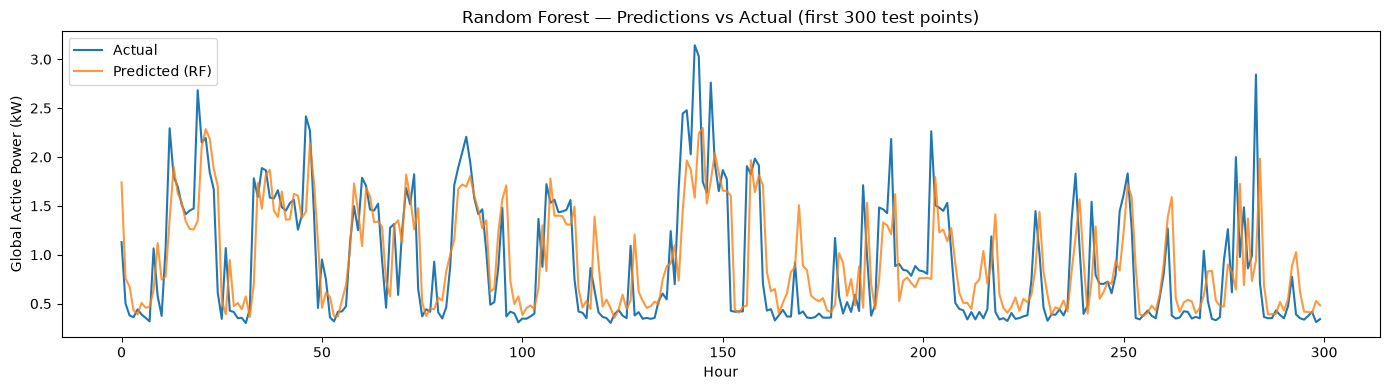

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_test[:300], label="Actual", linewidth=1.5)
ax.plot(y_pred_rf[:300], label="Predicted (RF)", linewidth=1.5, alpha=0.8)
ax.set_title("Random Forest — Predictions vs Actual (first 300 test points)")
ax.set_ylabel("Global Active Power (kW)")
ax.set_xlabel("Hour")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
baseline_results = {
    "model": "RandomForest",
    "RMSE": float(rmse),
    "MAE": float(mae),
    "MAPE": float(mape),
    "R2": float(r2),
    "latency_ms_per_sample": float(latency_per_sample_ms),
}

with open("../data/processed/baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=2)

print("Saved baseline_results.json")
print(baseline_results)

Saved baseline_results.json
{'model': 'RandomForest', 'RMSE': 0.4864631941953724, 'MAE': 0.3342665846028032, 'MAPE': 44.862333906875634, 'R2': 0.5301624105454336, 'latency_ms_per_sample': 0.039260035142821996}
